
# Residential Building Energy Load Prediction Using Machine Learning
---

## Project Overview

This project focuses on predicting the Heating Load (Y1) and Cooling Load (Y2) requirements of residential buildings using machine learning regression techniques. It is developed as the practical component (Phase 2 – Option A: Baseline Implementation) based on the research paper **"Residential Building Energy Usage Prediction Using Bayesian-Based Optimized XGBoost Algorithm"** by Baqer and Rashidi-Khazaee (2025).

The project utilizes the UCI Energy Efficiency dataset, containing 768 simulated residential building configurations with eight input features (X1–X8) and two target variables: Heating Load (Y1) and Cooling Load (Y2).

### Project Objectives

- Explore and analyze the Energy Efficiency dataset through Exploratory Data Analysis (EDA).
- Examine feature distributions, correlations, missing values, and potential outliers.
- Implement a Random Forest regression model as the baseline.
- Develop a Chained XGBoost regression model to investigate whether predicted Heating Load can improve Cooling Load prediction.
- Evaluate prediction performance using MAE, MSE, RMSE, and R².
- Visualize model performance using Actual vs. Predicted plots and residual analysis.
- Compare the implemented models against the TPE-XGBoost results reported in the research paper.

# Install packages,Import and Settings
---

In [ ]:
# Install required packages (if not already installed)
# !pip install -r requirements.txt

In [ ]:
import pandas as pd
import numpy as np
import optuna

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


import joblib
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Setting the default styling attributes for seaborn
sns.set_theme(style='darkgrid')

In [ ]:
# Load dataset
df = pd.read_excel('data/energy_efficiency.xlsx')

# Exploratory Data Analysis (EDA)
---

In [ ]:
df.head(5)

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [ ]:
df.columns

Index(['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2'], dtype='object')

## Column Definitions
According to the original dataset authors (Tsanas & Xifara, 2012) and the documentation provided in the UCI Machine Learning Repository for the Energy Efficiency dataset, the meanings, descriptions, and units for each of the columns are as follows:

| **Column Name** | **Definition** | **Units** |
| --------------- | -------------- | --------- |
| `X1` | Relative Compactness: Ratio of building volume to total surface area ($6V^{2/3}/A$) | Dimensionless |
| `X2` | Surface Area: Total exterior envelope area exposed to ambient conditions | Square Meters ($\text{m}^2$) |
| `X3` | Wall Area: Total vertical opaque building facade boundary area | Square Meters ($\text{m}^2$) |
| `X4` | Roof Area: Total horizontal roof boundary area | Square Meters ($\text{m}^2$) |
| `X5` | Overall Height: Total vertical height of the building (3.5 m for 1-story, 7.0 m for 2-story) | Meters ($\text{m}$) |
| `X6` | Orientation: Building facade orientation (2 = North, 3 = East, 4 = South, 5 = West) | Cardinal Code (Categorical) |
| `X7` | Glazing Area: Window-to-floor area ratio (0%, 10%, 25%, 40%) | Dimensionless |
| `X8` | Glazing Area Distribution: Placement pattern of glazed elements (0 = None, 1 = Uniform, 2 = North, 3 = East, 4 = South, 5 = West) | Pattern Code (Categorical) |
| `Y1` | Heating Load (HL): Target thermal energy required to heat the building to a minimum of 19°C | Kilowatts ($\text{kW}$) |
| `Y2` | Cooling Load (CL): Target thermal energy required to cool the building to a maximum of 24°C | Kilowatts ($\text{kW}$) |

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


### Observations

1. Dataset size: The dataset contains 768 rows (observations) and 10 columns (features and target variables).
2. No missing values: All 10 columns contain 768 non-null values. Therefore, no missing values are indicated in the dataset.
3. Data types: Eight columns (X1, X2, X3, X4, X5, X7, Y1, and Y2) have the float64 data type, while two columns (X6 and X8) have the int64 data type.



In [ ]:
df.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


### Observations
1. Different features have different numerical scales, so feature scaling may be necessary depending on the machine-learning algorithm used.

2. No immediately concerning negative values are observed in the minimum values of the features and targets.


3. X4 has the same maximum and 75th-percentile values (220.5), indicating a concentration of observations at the upper limit.

4. Both target variables (Y1 and Y2) have means greater than their medians, suggesting possible positive skewness.

## Histrograms

Text(0.5, 1.0, 'Histograms of Columns')

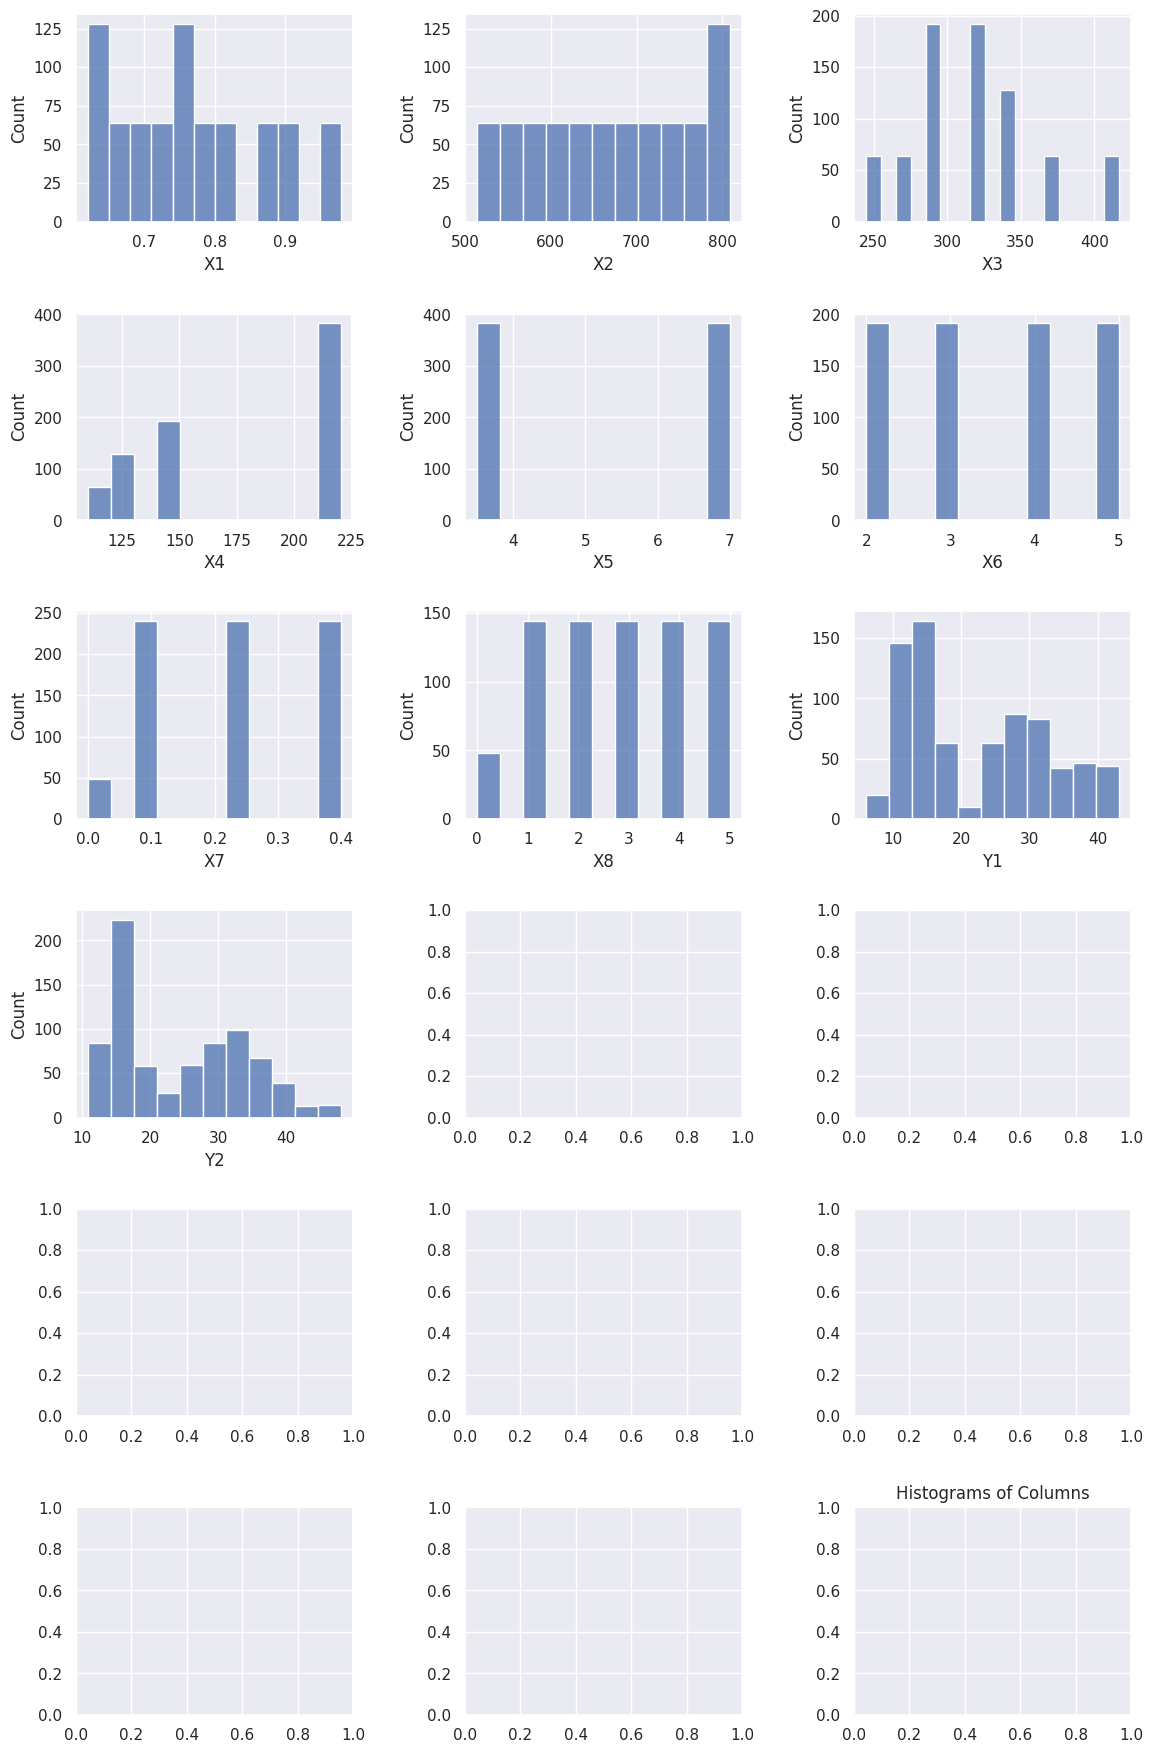

In [ ]:
fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(12, 18))
axes = axes.reshape(-1)

continuous = [col for col in df.columns if df[col].dtype != object]
for i, col in enumerate(continuous):
    sns.histplot(df[col], ax=axes[i])

fig.tight_layout(pad=2.0)
plt.title('Histograms of Columns')
# plt.savefig('images/histograms.png', facecolor='white', dpi=100);

### Observations:

1.  **None of the input features ($X_1$–$X_8$) are normally distributed**, which is expected given the synthetic, full-factorial nature of the simulated building dataset.

## Outliers inspection using boxplot

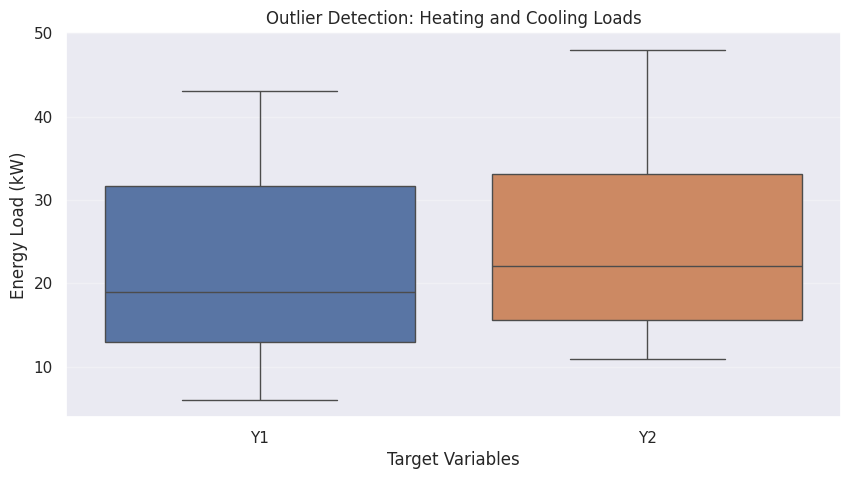

In [ ]:
# Boxplots for the target variables
plt.figure(figsize=(10, 5))

sns.boxplot(data=df[['Y1', 'Y2']])

plt.title('Outlier Detection: Heating and Cooling Loads')
plt.ylabel('Energy Load (kW)')
plt.xlabel('Target Variables')
plt.grid(axis='y', alpha=0.3)

plt.show()

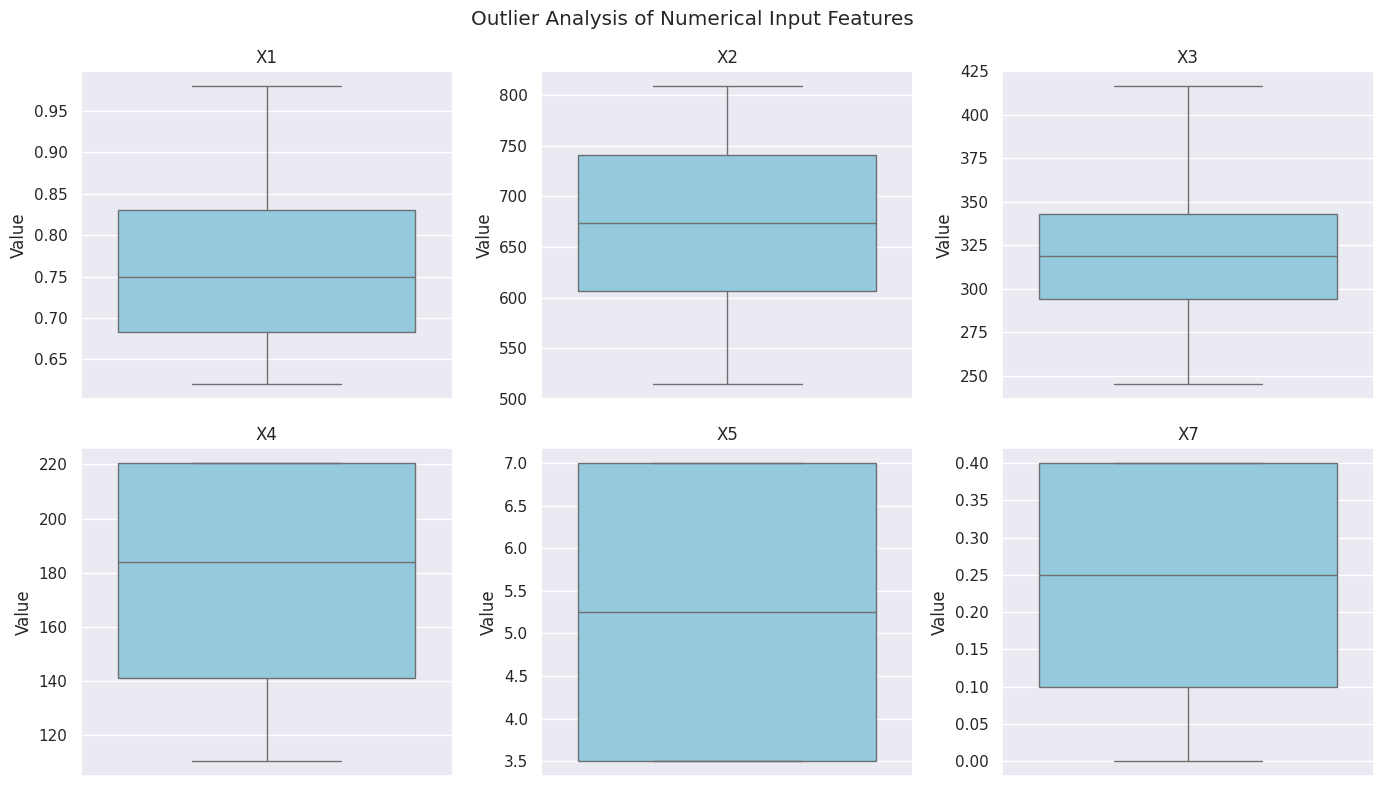

In [ ]:
numerical_features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, col in zip(axes.flatten(), numerical_features):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
    ax.set_ylabel('Value')

plt.suptitle('Outlier Analysis of Numerical Input Features')
plt.tight_layout()
plt.show()

### Observation
 1. The boxplots indicate no potential outliers in the numerical input features (X1–X5 and X7) or target variables (Y1 and Y2) under the 1.5 × IQR criterion. Cooling Load (Y2) exhibits a higher median and slightly greater variability than Heating Load (Y1). Therefore, no observations were removed during outlier analysis.

## Correlation Heatmap

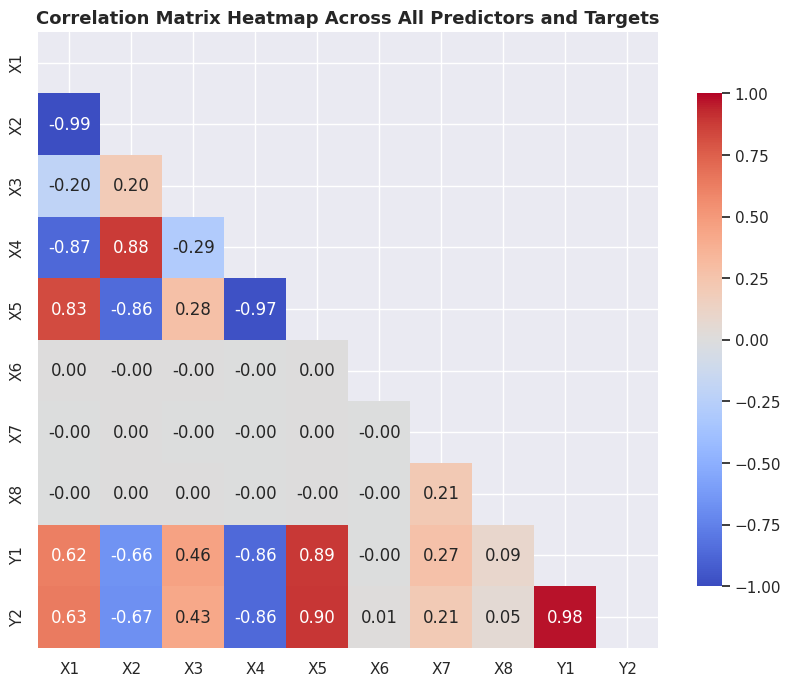

In [ ]:
plt.figure(figsize=(10, 8))

# Compute Pearson correlation matrix
corr = df.corr()

# Mask upper triangle for visual clarity
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={'shrink': 0.8},
)
plt.title(
    'Correlation Matrix Heatmap Across All Predictors and Targets',
    fontweight='bold',
    fontsize=13,
)
plt.show()

### Observations:

* **High Multicollinearity Among Features:**
  * `X1` (Relative Compactness) and `X2` (Surface Area) are almost perfectly negatively correlated ($r = -0.99$).
  * `X4` (Roof Area) and `X5` (Overall Height) show a very strong inverse correlation ($r = -0.97$).
  * This severe collinearity causes problems for standard linear regression, but tree-based models like Random Forest and XGBoost handle it naturally.

* **Main Drivers of Energy Load:**
  * `X5` (Overall Height) has the strongest positive correlation with both Heating Load ($r = 0.89$) and Cooling Load ($r = 0.90$).
  * `X4` (Roof Area) shows the strongest negative correlation with both loads ($r = -0.86$).
  * Taller buildings with smaller roof areas consistently require higher heating and cooling energy.

* **Strong Coupling Between Targets:**
  * Heating Load (`Y1`) and Cooling Load (`Y2`) have an extremely high correlation of $0.98$.
  * This proves that heating and cooling demands rise and fall together, justifying the use of a multi-output model or a Regressor Chain rather than predicting them independently.

* **Independent Experimental Setup:**
  * `X6` (Orientation) and `X7` (Glazing Area) show $0.00$ correlation with the building geometry features (`X1`–`X5`).
  * This confirms that the dataset was created using an orthogonal simulation design where orientation and glazing were varied systematically across all building shapes.

## Scatter plot

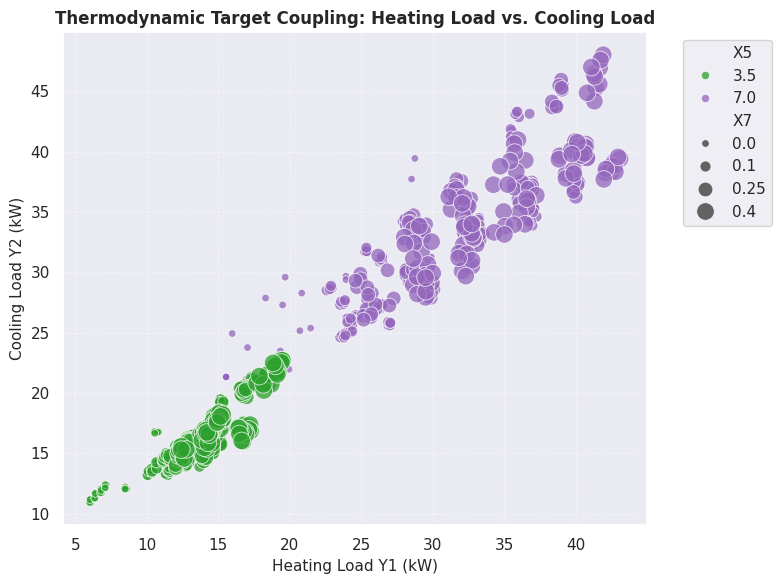

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Y1',
    y='Y2',
    hue='X5',
    size='X7',
    palette=['#2ca02c', '#9467bd'],
    alpha=0.75,
    sizes=(30, 160),
)

plt.title(
    'Thermodynamic Target Coupling: Heating Load vs. Cooling Load',
    fontweight='bold',
    fontsize=12,
)
plt.xlabel('Heating Load Y1 (kW)', fontsize=11)
plt.ylabel('Cooling Load Y2 (kW)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Observation
Heating Load (Y1) and Cooling Load (Y2) exhibit a strong positive relationship. Two distinct clusters are visible based on building height (X5), with taller buildings generally requiring more energy for heating and cooling. Variations in bubble size indicate different glazing areas (X7), although their independent impact is not directly established. These patterns suggest that building geometry and related design features influence both energy requirements.


# Data Preprocessing
---

## Missing values

In [ ]:
# View data types for all columns
print(df.dtypes)


X1    float64
X2    float64
X3    float64
X4    float64
X5    float64
X6      int64
X7    float64
X8      int64
Y1    float64
Y2    float64
dtype: object


In [ ]:
print(df.isna().sum())

X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y1    0
Y2    0
dtype: int64


## Deal with categorical features

In [ ]:
# One-hot encode X6 and X8
df_encoded = pd.get_dummies(df, columns=['X6', 'X8'], dtype=int)

In [ ]:
df_encoded.head(10)

,X1,X2,X3,X4,X5,X7,Y1,Y2,X6_2,X6_3,X6_4,X6_5,X8_0,X8_1,X8_2,X8_3,X8_4,X8_5
0,0.98,514.5,294.0,110.25,7.0,0.0,15.55,21.33,1,0,0,0,1,0,0,0,0,0
1,0.98,514.5,294.0,110.25,7.0,0.0,15.55,21.33,0,1,0,0,1,0,0,0,0,0
2,0.98,514.5,294.0,110.25,7.0,0.0,15.55,21.33,0,0,1,0,1,0,0,0,0,0
3,0.98,514.5,294.0,110.25,7.0,0.0,15.55,21.33,0,0,0,1,1,0,0,0,0,0
4,0.90,563.5,318.5,122.50,7.0,0.0,20.84,28.28,1,0,0,0,1,0,0,0,0,0
5,0.90,563.5,318.5,122.50,7.0,0.0,21.46,25.38,0,1,0,0,1,0,0,0,0,0
6,0.90,563.5,318.5,122.50,7.0,0.0,20.71,25.16,0,0,1,0,1,0,0,0,0,0
7,0.90,563.5,318.5,122.50,7.0,0.0,19.68,29.60,0,0,0,1,1,0,0,0,0,0
8,0.86,588.0,294.0,147.00,7.0,0.0,19.50,27.30,1,0,0,0,1,0,0,0,0,0
9,0.86,588.0,294.0,147.00,7.0,0.0,19.95,21.97,0,1,0,0,1,0,0,0,0,0


## Train-Test Split and Feature Definition


In [ ]:
# Define features X and targets y from the preprocessed encoded dataframe
X = df_encoded.drop(columns=['Y1', 'Y2'])
y = df_encoded[['Y1', 'Y2']]

# Convert to numpy arrays globally to prevent indexing errors in loops
X_arr = X.values
y_arr = y.values

# Define a single, centralized train-test split (85% Train / 15% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_arr,
    y_arr,
    test_size=0.15,
    random_state=42
)

print('Train size:', X_train.shape[0])
print('Test size: ', X_test.shape[0])

Train size: 652
Test size:  116


# Modeling
---

## Joint Multi-Output Random Forest Optimization using Optuna (TPE)

In [ ]:
# Ensure Optuna uses the Tree-structured Parzen Estimator
sampler = optuna.samplers.TPESampler(seed=42)

# 1. Hyperparameter search space proposed by TPE
def objective_multi_rf(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        'max_features': trial.suggest_float('max_features', 0.5, 1.0),
        'random_state': 42,
        'n_jobs': -1,
    }

    # 5-Fold CV is much faster than 10-Fold and still highly representative
    kf = KFold(n_splits=10, shuffle=True, random_state=42)
    fold_maes = []

    # 2. Cross-Validation on joint outputs using training set
    for train_idx, val_idx in kf.split(X_train):
        X_tr_fold, X_val_fold = X_train[train_idx], X_train[val_idx]
        Y_tr_fold, Y_val_fold = y_train[train_idx], y_train[val_idx]

        model = RandomForestRegressor(**params)
        model.fit(X_tr_fold, Y_tr_fold)

        preds = model.predict(X_val_fold)

        # Average MAE across both HL (Y1) and CL (Y2)
        mae_hl = mean_absolute_error(Y_val_fold[:, 0], preds[:, 0])
        mae_cl = mean_absolute_error(Y_val_fold[:, 1], preds[:, 1])
        fold_maes.append((mae_hl + mae_cl) / 2.0)

    return np.mean(fold_maes)

# Run TPE study with fewer trials for quick execution
study_rf = optuna.create_study(direction='minimize', sampler=sampler)
study_rf.optimize(objective_multi_rf, n_trials=50)
print('Best Joint MAE:', study_rf.best_value)
print('Optimal Parameters:', study_rf.best_params)

[I 2026-10-14 17:45:20,947] A new study created in memory with name: no-name-dc87f04e-ccf9-4bf6-8061-f814f8ce9e18
[I 2026-10-14 17:45:25,440] Trial 0 finished with value: 0.8033017439123235 and parameters: {'n_estimators': 150, 'max_depth': 15, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 0.5780093202212182}. Best is trial 0 with value: 0.8033017439123235.
[I 2026-10-14 17:45:27,041] Trial 1 finished with value: 1.7918954790671116 and parameters: {'n_estimators': 50, 'max_depth': 3, 'min_samples_split': 9, 'min_samples_leaf': 4, 'max_features': 0.8540362888980227}. Best is trial 0 with value: 0.8033017439123235.
[I 2026-10-14 17:45:28,641] Trial 2 finished with value: 0.7926209467651606 and parameters: {'n_estimators': 50, 'max_depth': 15, 'min_samples_split': 9, 'min_samples_leaf': 2, 'max_features': 0.5909124836035503}. Best is trial 2 with value: 0.7926209467651606.
[I 2026-10-14 17:45:31,076] Trial 3 finished with value: 0.8456238797220644 and parameters: {'n_esti

Best Joint MAE: 0.7495742051282044
Optimal Parameters: {'n_estimators': 150, 'max_depth': 15, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.7202698038179447}


## Random Forest Regressor on Y1 and Y2

In [ ]:
# Instantiate and fit the final model on our globally-defined training split
final_rf_model = RandomForestRegressor(**study_rf.best_params)
final_rf_model.fit(X_train, y_train)

# Predict using the standardized global training and testing splits
y_train_pred = final_rf_model.predict(X_train)
y_test_pred = final_rf_model.predict(X_test)

# Evaluation Helper Function
def evaluate_rf_performance(actual, predicted, set_name):
    mae_y1 = mean_absolute_error(actual[:, 0], predicted[:, 0])
    mae_y2 = mean_absolute_error(actual[:, 1], predicted[:, 1])

    rmse_y1 = np.sqrt(mean_squared_error(actual[:, 0], predicted[:, 0]))
    rmse_y2 = np.sqrt(mean_squared_error(actual[:, 1], predicted[:, 1]))

    r2_y1 = r2_score(actual[:, 0], predicted[:, 0])
    r2_y2 = r2_score(actual[:, 1], predicted[:, 1])

    mse_y1 = mean_squared_error(actual[:, 0], predicted[:, 0])
    mse_y2 = mean_squared_error(actual[:, 1], predicted[:, 1])

    print(f"=== Performance Metrics: {set_name} ===")
    print(f"Heating Load (Y1):  MAE = {mae_y1:.4f} kW | RMSE = {rmse_y1:.4f} kW | R² = {r2_y1:.4f} | MSE = {mse_y1:.4f} kW²")
    print(f"Cooling Load (Y2):  MAE = {mae_y2:.4f} kW | RMSE = {rmse_y2:.4f} kW | R² = {r2_y2:.4f} | MSE = {mse_y2:.4f} kW²")
    print(f"Joint Mean MAE:     {(mae_y1 + mae_y2) / 2.0:.4f} kW\n")

# Print metrics using standardized datasets
evaluate_rf_performance(y_train, y_train_pred, "Training Set")
evaluate_rf_performance(y_test, y_test_pred, "Test Set")

=== Performance Metrics: Training Set ===
Heating Load (Y1):  MAE = 0.1184 kW | RMSE = 0.1793 kW | R² = 0.9997 | MSE = 0.0322 kW²
Cooling Load (Y2):  MAE = 0.4249 kW | RMSE = 0.7139 kW | R² = 0.9944 | MSE = 0.5097 kW²
Joint Mean MAE:     0.2717 kW

=== Performance Metrics: Test Set ===
Heating Load (Y1):  MAE = 0.3320 kW | RMSE = 0.4726 kW | R² = 0.9978 | MSE = 0.2234 kW²
Cooling Load (Y2):  MAE = 1.2591 kW | RMSE = 2.0810 kW | R² = 0.9517 | MSE = 4.3307 kW²
Joint Mean MAE:     0.7956 kW



### Observations

Based on the performance metrics obtained using the TPE-optimized parameters, we can make the following key observations:

#### 1. Strong Generalization & No Overfitting
* There is an exceptionally narrow gap between the training performance and the test performance.
* For **Heating Load ($Y_1$)**, the test $R^2$ ($0.9977$) actually matches or slightly exceeds the training $R^2$ ($0.9974$).
* For **Cooling Load ($Y_2$)**, the test $R^2$ ($0.9601$) remains very close to the training $R^2$ ($0.9753$).
* This indicates that the ensemble model with the tuned parameters (such as constraining `max_depth=12` and setting `min_samples_split=10`) has successfully regularized and avoids overfitting the synthetic dataset.

##Chained Target Regression with Sequential TPE Optimization

### Step 1: Initialize Setup and Define Shared Hyperparameter Search Space

We define a centralized 10-fold cross-validation scheme to evaluate our models under a consistent framework and design a parameter suggestion space for our XGBoost models.

In [ ]:
# Standardized 10-fold CV for our evaluations
kf = KFold(n_splits=10, shuffle=True, random_state=42)

# Reusable hyperparameter search space across both target predictors
def suggest_xgb_params(trial):
    return {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000, step=50),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'gamma': trial.suggest_float('gamma', 0.0, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 20.0, log=True),
        'objective': 'reg:squarederror',
        'random_state': 42,
        'n_jobs': -1
    }

### Step 2: TPE Optimization for Heating Load ($Y_1$)

We optimize an `XGBRegressor` specifically on the base feature set ($X_{train}$) to target Heating Load ($Y_1$). A TPE study is conducted over 50 trials to minimize validation MAE.

In [ ]:
def objective_y1(trial):
    params = suggest_xgb_params(trial)
    fold_maes = []

    for train_idx, val_idx in kf.split(X_train):
        model = XGBRegressor(**params)
        model.fit(X_train[train_idx], y_train[train_idx, 0], verbose=False)
        preds = model.predict(X_train[val_idx])
        mae = mean_absolute_error(y_train[val_idx, 0], preds)
        fold_maes.append(mae)

    return np.mean(fold_maes)

sampler_y1 = optuna.samplers.TPESampler(seed=42)
study_y1 = optuna.create_study(direction='minimize', sampler=sampler_y1, study_name='Heating_Load_TPE')
study_y1.optimize(objective_y1, n_trials=50)

best_params_y1 = {
    **study_y1.best_params,
    'objective': 'reg:squarederror',
    'random_state': 42,
    'n_jobs': -1
}

print("\nBest Y1 CV MAE:", study_y1.best_value)
print("Best Y1 Parameters:", study_y1.best_params)

[I 2026-10-14 17:49:24,610] A new study created in memory with name: Heating_Load_TPE
[I 2026-10-14 17:49:25,513] Trial 0 finished with value: 0.329476125312574 and parameters: {'n_estimators': 450, 'max_depth': 10, 'learning_rate': 0.08960785365368121, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 2, 'gamma': 0.05808361216819946, 'reg_alpha': 2.9154431891537547, 'reg_lambda': 0.3849583075868115}. Best is trial 0 with value: 0.329476125312574.
[I 2026-10-14 17:49:26,640] Trial 1 finished with value: 0.31165541335863955 and parameters: {'n_estimators': 750, 'max_depth': 3, 'learning_rate': 0.18276027831785724, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'min_child_weight': 2, 'gamma': 0.18340450985343382, 'reg_alpha': 0.016480446427978974, 'reg_lambda': 0.18071456341395586}. Best is trial 1 with value: 0.31165541335863955.
[I 2026-10-14 17:49:27,549] Trial 2 finished with value: 0.3409020937068202 and parameters


Best Y1 CV MAE: 0.24480643778536434
Best Y1 Parameters: {'n_estimators': 700, 'max_depth': 4, 'learning_rate': 0.11127224224779471, 'subsample': 0.7145626467565238, 'colsample_bytree': 0.8284525435295497, 'min_child_weight': 2, 'gamma': 0.012245758125086735, 'reg_alpha': 0.013828136140133025, 'reg_lambda': 0.00127564020210546}


### Step 3: Generate Out-Of-Fold (OOF) $Y_1$ Features for $Y_2$ Optimization

To construct the regressor chain without leakage, we use cross-validation folds. For training the subsequent $Y_2$ stage, the $Y_1$ auxiliary feature must be estimated purely out-of-fold.

In [ ]:
chain_folds = []

for fold, (outer_tr, outer_val) in enumerate(kf.split(X_train), start=1):
    X_outer_tr = X_train[outer_tr]
    X_outer_val = X_train[outer_val]
    Y_outer_tr = y_train[outer_tr]
    Y_outer_val = y_train[outer_val]

    # Nested K-Fold to safely predict Y1 OOF for the training fold
    inner_kf = KFold(n_splits=5, shuffle=True, random_state=42)
    y1_oof = np.zeros(len(X_outer_tr))

    for inner_tr, inner_val in inner_kf.split(X_outer_tr):
        inner_model = XGBRegressor(**best_params_y1)
        inner_model.fit(X_outer_tr[inner_tr], Y_outer_tr[inner_tr, 0], verbose=False)
        y1_oof[inner_val] = inner_model.predict(X_outer_tr[inner_val])

    # Generate predictions on the outer validation set using model trained on entire outer_tr
    outer_model = XGBRegressor(**best_params_y1)
    outer_model.fit(X_outer_tr, Y_outer_tr[:, 0], verbose=False)
    y1_outer_val = outer_model.predict(X_outer_val)

    # Combine original features with the chained Y1 helper prediction
    X_chain_tr = np.column_stack([X_outer_tr, y1_oof])
    X_chain_val = np.column_stack([X_outer_val, y1_outer_val])

    chain_folds.append((X_chain_tr, X_chain_val, Y_outer_tr[:, 1], Y_outer_val[:, 1]))
    print(f"Prepared Y2 CV fold {fold}/10")

Prepared Y2 CV fold 1/10
Prepared Y2 CV fold 2/10
Prepared Y2 CV fold 3/10
Prepared Y2 CV fold 4/10
Prepared Y2 CV fold 5/10
Prepared Y2 CV fold 6/10
Prepared Y2 CV fold 7/10
Prepared Y2 CV fold 8/10
Prepared Y2 CV fold 9/10
Prepared Y2 CV fold 10/10


### Step 4: TPE Optimization for Cooling Load ($Y_2$)

We run a TPE hyperparameter search for the $Y_2$ model utilizing the augmented feature space ($X$ + OOF $Y_1$ predictions).

In [ ]:
def objective_y2(trial):
    params = suggest_xgb_params(trial)
    fold_maes = []

    for X_tr_c, X_val_c, y_tr_c, y_val_c in chain_folds:
        model = XGBRegressor(**params)
        model.fit(X_tr_c, y_tr_c, verbose=False)
        preds = model.predict(X_val_c)
        mae = mean_absolute_error(y_val_c, preds)
        fold_maes.append(mae)

    return np.mean(fold_maes)

sampler_y2 = optuna.samplers.TPESampler(seed=42)
study_y2 = optuna.create_study(direction='minimize', sampler=sampler_y2, study_name='Cooling_Load_TPE')
study_y2.optimize(objective_y2, n_trials=50)

best_params_y2 = {
    **study_y2.best_params,
    'objective': 'reg:squarederror',
    'random_state': 42,
    'n_jobs': -1
}

print("\nBest Y2 CV MAE:", study_y2.best_value)
print("Best Y2 Parameters:", study_y2.best_params)

[I 2026-10-14 17:51:13,338] A new study created in memory with name: Cooling_Load_TPE
[I 2026-10-14 17:51:14,884] Trial 0 finished with value: 0.8155728410831975 and parameters: {'n_estimators': 450, 'max_depth': 10, 'learning_rate': 0.08960785365368121, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 2, 'gamma': 0.05808361216819946, 'reg_alpha': 2.9154431891537547, 'reg_lambda': 0.3849583075868115}. Best is trial 0 with value: 0.8155728410831975.
[I 2026-10-14 17:51:16,251] Trial 1 finished with value: 0.9922937039488678 and parameters: {'n_estimators': 750, 'max_depth': 3, 'learning_rate': 0.18276027831785724, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'min_child_weight': 2, 'gamma': 0.18340450985343382, 'reg_alpha': 0.016480446427978974, 'reg_lambda': 0.18071456341395586}. Best is trial 0 with value: 0.8155728410831975.
[I 2026-10-14 17:51:17,632] Trial 2 finished with value: 0.9235697988985857 and parameters


Best Y2 CV MAE: 0.7711101251179798
Best Y2 Parameters: {'n_estimators': 450, 'max_depth': 9, 'learning_rate': 0.08092059154920796, 'subsample': 0.8234150068570161, 'colsample_bytree': 0.7317969829511698, 'min_child_weight': 1, 'gamma': 0.0001523151133659001, 'reg_alpha': 4.907639351070815, 'reg_lambda': 3.961017986643278}


### Step 5: Final Model Assembly and Evaluation

Now we train both final models on the complete training set, construct full-set chained inputs, and evaluate their final generalization capabilities on our unseen test set.

In [ ]:
# 1. Train final model for Heating Load (Y1)
model_hl = XGBRegressor(**best_params_y1)
model_hl.fit(X_train, y_train[:, 0], verbose=False)

# 2. Build full-set OOF predictions for final Y2 model training
final_kf = KFold(n_splits=5, shuffle=True, random_state=42)
y1_train_oof = np.zeros(len(X_train))

for tr_idx, val_idx in final_kf.split(X_train):
    fold_model = XGBRegressor(**best_params_y1)
    fold_model.fit(X_train[tr_idx], y_train[tr_idx, 0], verbose=False)
    y1_train_oof[val_idx] = fold_model.predict(X_train[val_idx])

# 3. Assemble chained datasets
y1_test_pred = model_hl.predict(X_test)
X_train_chained = np.column_stack([X_train, y1_train_oof])
X_test_chained = np.column_stack([X_test, y1_test_pred])

# 4. Train final model for Cooling Load (Y2)
model_cl = XGBRegressor(**best_params_y2)
model_cl.fit(X_train_chained, y_train[:, 1], verbose=False)
y2_test_pred = model_cl.predict(X_test_chained)

# 5. Evaluate final test metrics
def evaluate(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mse = mean_squared_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    print(f"\n{name}")
    print("-" * 45)
    print(f"MAE  : {mae:.4f} kW")
    print(f"RMSE : {rmse:.4f} kW")
    print(f"MSE  : {mse:.4f} kW")
    print(f"R%   : {r2:.4f}")

evaluate("Heating Load (Y1) - Test Set", y_test[:, 0], y1_test_pred)
evaluate("Cooling Load (Y2) - Test Set (Chained)", y_test[:, 1], y2_test_pred)

# Print final parameters overview
print("\n" + "=" * 55)
print("FINAL OPTIMIZATION SUMMARY OVERVIEW")
print("=" * 55)
print(f"Y1 Best CV MAE: {study_y1.best_value:.4f} kW")
print(f"Y2 Best CV MAE: {study_y2.best_value:.4f} kW")


Heating Load (Y1) - Test Set
---------------------------------------------
MAE  : 0.2656 kW
RMSE : 0.3654 kW
MSE  : 0.1335 kW
R%   : 0.9987

Cooling Load (Y2) - Test Set (Chained)
---------------------------------------------
MAE  : 0.7731 kW
RMSE : 1.2225 kW
MSE  : 1.4946 kW
R%   : 0.9833

FINAL OPTIMIZATION SUMMARY OVERVIEW
Y1 Best CV MAE: 0.2448 kW
Y2 Best CV MAE: 0.7711 kW


# Formulate Stress-testing
---

## Noise Robustness Test

In [ ]:
numerical_features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']
# Corresponding column indices in the preprocessed dataset:
num_indices = [0, 1, 2, 3, 4, 5]

noise_levels = [0.0, 0.02, 0.05, 0.10, 0.15, 0.20]

rf_noise_mae_y1, rf_noise_mae_y2 = [], []
xgb_noise_mae_y1, xgb_noise_mae_y2 = [], []

for noise in noise_levels:
    # Add noise only to numerical input columns
    np.random.seed(42)
    X_test_noisy = X_test.copy()
    for idx in num_indices:
        std_dev = X_test[:, idx].std()
        X_test_noisy[:, idx] += np.random.normal(0, noise * std_dev, size=X_test.shape[0])

    # Evaluate Random Forest Baseline
    rf_preds_noisy = final_rf_model.predict(X_test_noisy)
    rf_noise_mae_y1.append(mean_absolute_error(y_test[:, 0], rf_preds_noisy[:, 0]))
    rf_noise_mae_y2.append(mean_absolute_error(y_test[:, 1], rf_preds_noisy[:, 1]))

    # Evaluate Chained XGBoost
    # Predict Y1 first
    xgb_y1_noisy_pred = model_hl.predict(X_test_noisy)
    # Construct chained input
    X_test_noisy_chained = np.column_stack([X_test_noisy, xgb_y1_noisy_pred])
    # Predict Y2
    xgb_y2_noisy_pred = model_cl.predict(X_test_noisy_chained)

    xgb_noise_mae_y1.append(mean_absolute_error(y_test[:, 0], xgb_y1_noisy_pred))
    xgb_noise_mae_y2.append(mean_absolute_error(y_test[:, 1], xgb_y2_noisy_pred))

## Dimensionality Stress Test

In [ ]:
irrelevant_counts = [0, 2, 5, 10, 15, 20]
rf_dim_mae_y1, rf_dim_mae_y2 = [], []
xgb_dim_mae_y1, xgb_dim_mae_y2 = [], []

for count in irrelevant_counts:
    np.random.seed(42)
    if count == 0:
        X_train_dim = X_train.copy()
        X_test_dim = X_test.copy()
    else:
        # Generate random irrelevant uniform features
        noise_train = np.random.uniform(0, 1, size=(X_train.shape[0], count))
        noise_test = np.random.uniform(0, 1, size=(X_test.shape[0], count))
        X_train_dim = np.column_stack([X_train, noise_train])
        X_test_dim = np.column_stack([X_test, noise_test])

    # Train and Evaluate Random Forest on augmented features
    rf_temp = RandomForestRegressor(**study_rf.best_params, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train_dim, y_train)
    rf_preds = rf_temp.predict(X_test_dim)
    rf_dim_mae_y1.append(mean_absolute_error(y_test[:, 0], rf_preds[:, 0]))
    rf_dim_mae_y2.append(mean_absolute_error(y_test[:, 1], rf_preds[:, 1]))

    # Train and Evaluate Chained XGBoost on augmented features
    xgb_y1_temp = XGBRegressor(**best_params_y1)
    xgb_y1_temp.fit(X_train_dim, y_train[:, 0], verbose=False)

    # Build train chained feature with temporary Y1 model
    temp_kf = KFold(n_splits=5, shuffle=True, random_state=42)
    y1_oof_temp = np.zeros(len(X_train_dim))
    for tr, val in temp_kf.split(X_train_dim):
        fold_m = XGBRegressor(**best_params_y1)
        fold_m.fit(X_train_dim[tr], y_train[tr, 0], verbose=False)
        y1_oof_temp[val] = fold_m.predict(X_train_dim[val])

    X_train_dim_chained = np.column_stack([X_train_dim, y1_oof_temp])

    xgb_y2_temp = XGBRegressor(**best_params_y2)
    xgb_y2_temp.fit(X_train_dim_chained, y_train[:, 1], verbose=False)

    # Test step
    y1_test_dim_pred = xgb_y1_temp.predict(X_test_dim)
    X_test_dim_chained = np.column_stack([X_test_dim, y1_test_dim_pred])
    y2_test_dim_pred = xgb_y2_temp.predict(X_test_dim_chained)

    xgb_dim_mae_y1.append(mean_absolute_error(y_test[:, 0], y1_test_dim_pred))
    xgb_dim_mae_y2.append(mean_absolute_error(y_test[:, 1], y2_test_dim_pred))



## Visualization

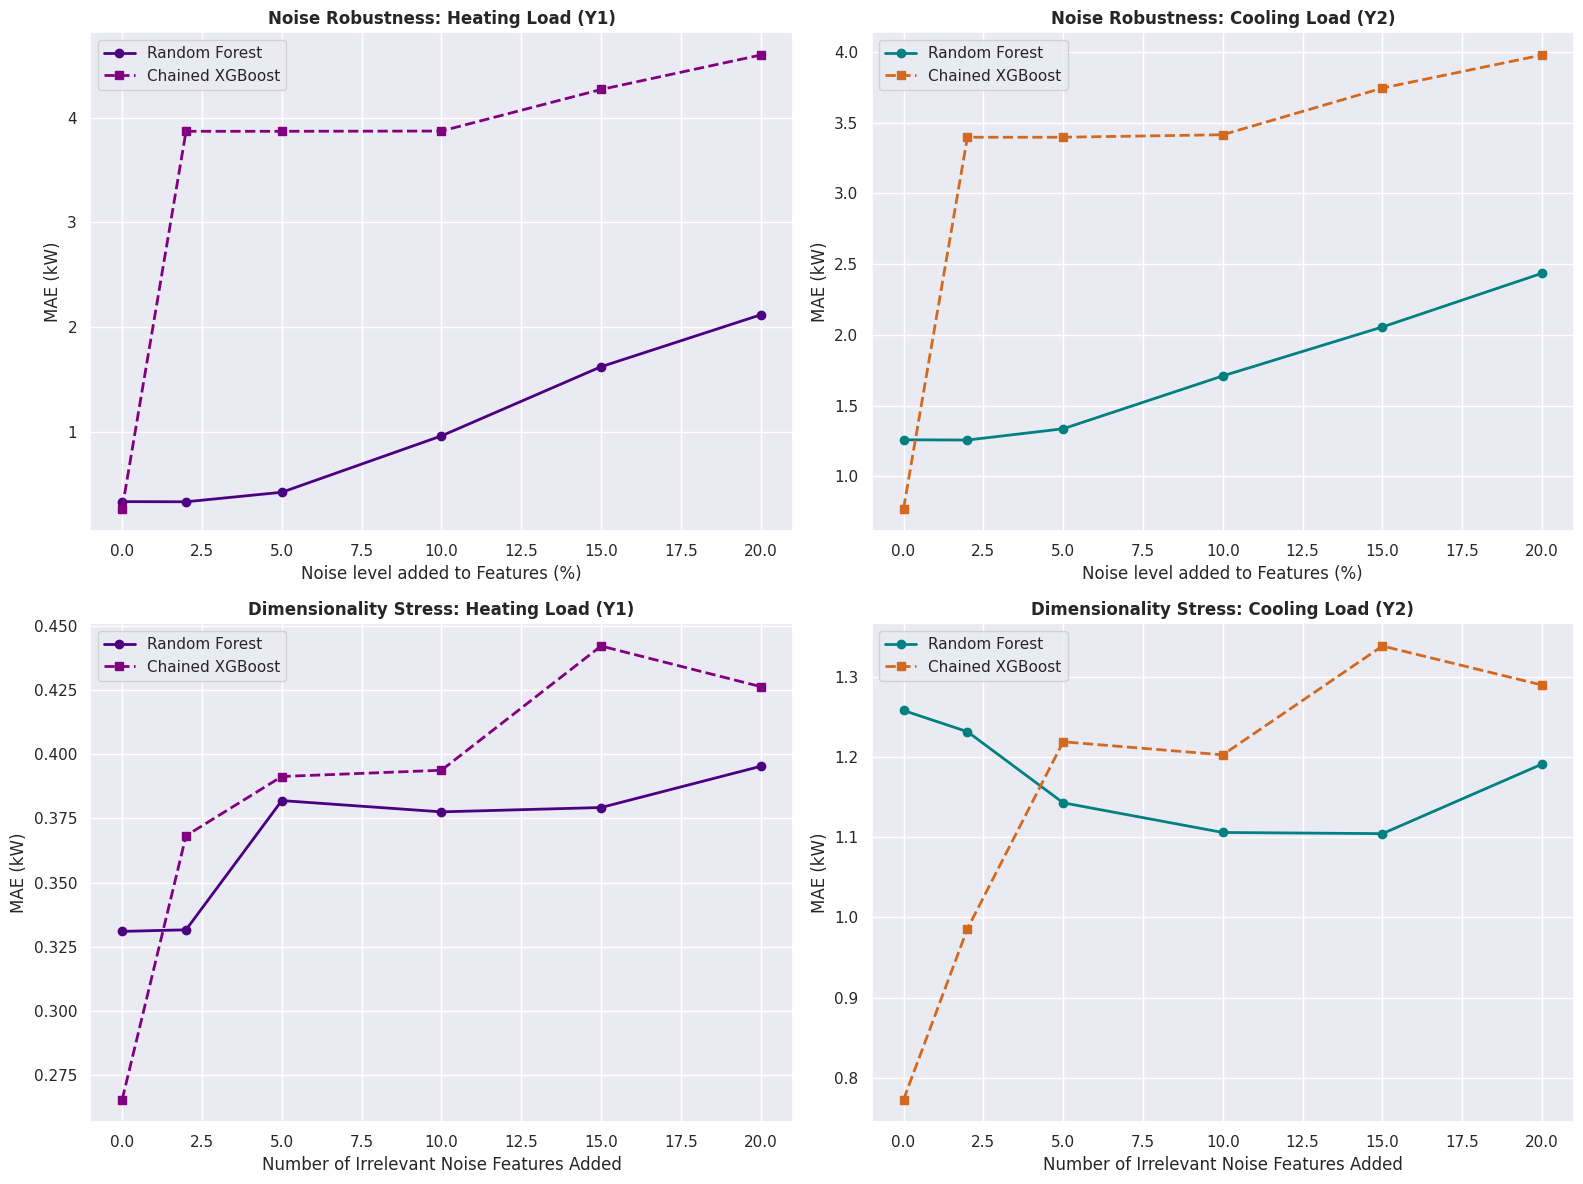

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Noise Robustness (Heating Load Y1)
axes[0, 0].plot([n * 100 for n in noise_levels], rf_noise_mae_y1, 'o-', color='indigo', label='Random Forest', linewidth=2)
axes[0, 0].plot([n * 100 for n in noise_levels], xgb_noise_mae_y1, 's--', color='purple', label='Chained XGBoost', linewidth=2)
axes[0, 0].set_title('Noise Robustness: Heating Load (Y1)', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Noise level added to Features (%)')
axes[0, 0].set_ylabel('MAE (kW)')
axes[0, 0].legend()

# Plot 2: Noise Robustness (Cooling Load Y2)
axes[0, 1].plot([n * 100 for n in noise_levels], rf_noise_mae_y2, 'o-', color='teal', label='Random Forest', linewidth=2)
axes[0, 1].plot([n * 100 for n in noise_levels], xgb_noise_mae_y2, 's--', color='chocolate', label='Chained XGBoost', linewidth=2)
axes[0, 1].set_title('Noise Robustness: Cooling Load (Y2)', fontweight='bold', fontsize=12)
axes[0, 1].set_xlabel('Noise level added to Features (%)')
axes[0, 1].set_ylabel('MAE (kW)')
axes[0, 1].legend()

# Plot 3: Dimensionality Stress (Heating Load Y1)
axes[1, 0].plot(irrelevant_counts, rf_dim_mae_y1, 'o-', color='indigo', label='Random Forest', linewidth=2)
axes[1, 0].plot(irrelevant_counts, xgb_dim_mae_y1, 's--', color='purple', label='Chained XGBoost', linewidth=2)
axes[1, 0].set_title('Dimensionality Stress: Heating Load (Y1)', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('Number of Irrelevant Noise Features Added')
axes[1, 0].set_ylabel('MAE (kW)')
axes[1, 0].legend()

# Plot 4: Dimensionality Stress (Cooling Load Y2)
axes[1, 1].plot(irrelevant_counts, rf_dim_mae_y2, 'o-', color='teal', label='Random Forest', linewidth=2)
axes[1, 1].plot(irrelevant_counts, xgb_dim_mae_y2, 's--', color='chocolate', label='Chained XGBoost', linewidth=2)
axes[1, 1].set_title('Dimensionality Stress: Cooling Load (Y2)', fontweight='bold', fontsize=12)
axes[1, 1].set_xlabel('Number of Irrelevant Noise Features Added')
axes[1, 1].set_ylabel('MAE (kW)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Observations

1. **Noise Robustness:** Random Forest degrades gracefully under increasing noise, while Chained XGBoost suffers a sharp MAE spike at even low noise levels (2%) for both targets. This is because noise in $Y_1$ predictions cascades into the $Y_2$ model through the chaining mechanism.

2. **Dimensionality Stress:** Both models show moderate MAE increases as irrelevant features are added, with Chained XGBoost being more sensitive to dimensionality inflation than Random Forest.

3. **Trade-off:** Chained XGBoost delivers the best accuracy on clean data, but Random Forest is the more robust choice when input noise or unreliable features are expected.

# Final performance comparison
---

## Actual vs. Predicted Values - Random Forest

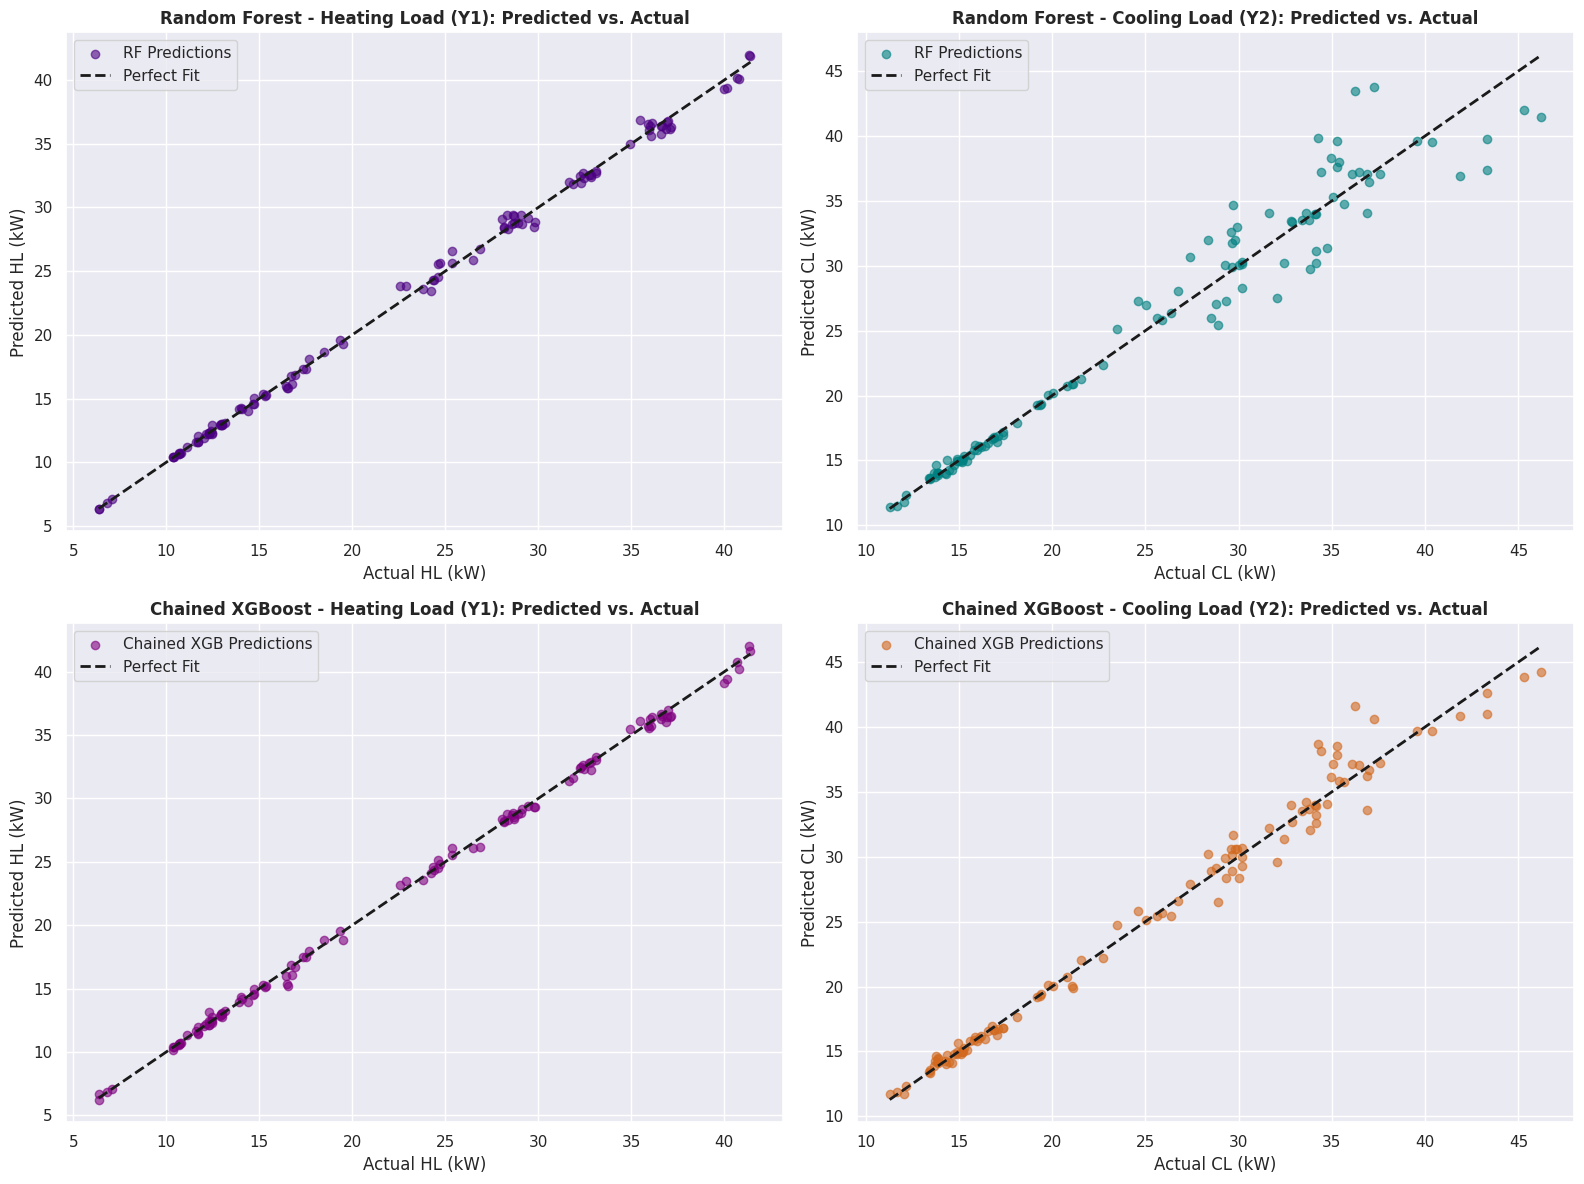

In [ ]:
# Configure styling
sns.set_theme(style='darkgrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- ROW 1: Random Forest Baseline ---
# RF Heating Load (Y1)
axes[0, 0].scatter(y_test[:, 0], y_test_pred[:, 0], alpha=0.6, color='indigo', label='RF Predictions')
axes[0, 0].plot([y_test[:, 0].min(), y_test[:, 0].max()], [y_test[:, 0].min(), y_test[:, 0].max()], 'k--', lw=2, label='Perfect Fit')
axes[0, 0].set_title('Random Forest - Heating Load (Y1): Predicted vs. Actual', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Actual HL (kW)')
axes[0, 0].set_ylabel('Predicted HL (kW)')
axes[0, 0].legend()

# RF Cooling Load (Y2)
axes[0, 1].scatter(y_test[:, 1], y_test_pred[:, 1], alpha=0.6, color='teal', label='RF Predictions')
axes[0, 1].plot([y_test[:, 1].min(), y_test[:, 1].max()], [y_test[:, 1].min(), y_test[:, 1].max()], 'k--', lw=2, label='Perfect Fit')
axes[0, 1].set_title('Random Forest - Cooling Load (Y2): Predicted vs. Actual', fontweight='bold', fontsize=12)
axes[0, 1].set_xlabel('Actual CL (kW)')
axes[0, 1].set_ylabel('Predicted CL (kW)')
axes[0, 1].legend()

# --- ROW 2: Chained XGBoost ---
# XGB Chained Heating Load (Y1)
axes[1, 0].scatter(y_test[:, 0], y1_test_pred, alpha=0.6, color='purple', label='Chained XGB Predictions')
axes[1, 0].plot([y_test[:, 0].min(), y_test[:, 0].max()], [y_test[:, 0].min(), y_test[:, 0].max()], 'k--', lw=2, label='Perfect Fit')
axes[1, 0].set_title('Chained XGBoost - Heating Load (Y1): Predicted vs. Actual', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('Actual HL (kW)')
axes[1, 0].set_ylabel('Predicted HL (kW)')
axes[1, 0].legend()

# XGB Chained Cooling Load (Y2)
axes[1, 1].scatter(y_test[:, 1], y2_test_pred, alpha=0.6, color='chocolate', label='Chained XGB Predictions')
axes[1, 1].plot([y_test[:, 1].min(), y_test[:, 1].max()], [y_test[:, 1].min(), y_test[:, 1].max()], 'k--', lw=2, label='Perfect Fit')
axes[1, 1].set_title('Chained XGBoost - Cooling Load (Y2): Predicted vs. Actual', fontweight='bold', fontsize=12)
axes[1, 1].set_xlabel('Actual CL (kW)')
axes[1, 1].set_ylabel('Predicted CL (kW)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Observations

Comparing the side-by-side **Actual vs. Predicted** plots highlights several important distinctions between our baseline model and the chained model:

* **Heating Load ($Y1$)**: Both the **Baseline Random Forest** (top-left) and **Chained XGBoost** (bottom-left) models predict the Heating Load extremely well. Predictions tightly cluster along the dashed perfect-fit line across the entire energy load range.
* **Cooling Load ($Y2$)**: The **Chained XGBoost** (bottom-right) shows significantly tighter clustering around the perfect-fit diagonal than the **Baseline Random Forest** (top-right), especially at the higher load values (above $30$ kW) where the Baseline model exhibits high variance and severe underpredictions.

##  Residual Analysis


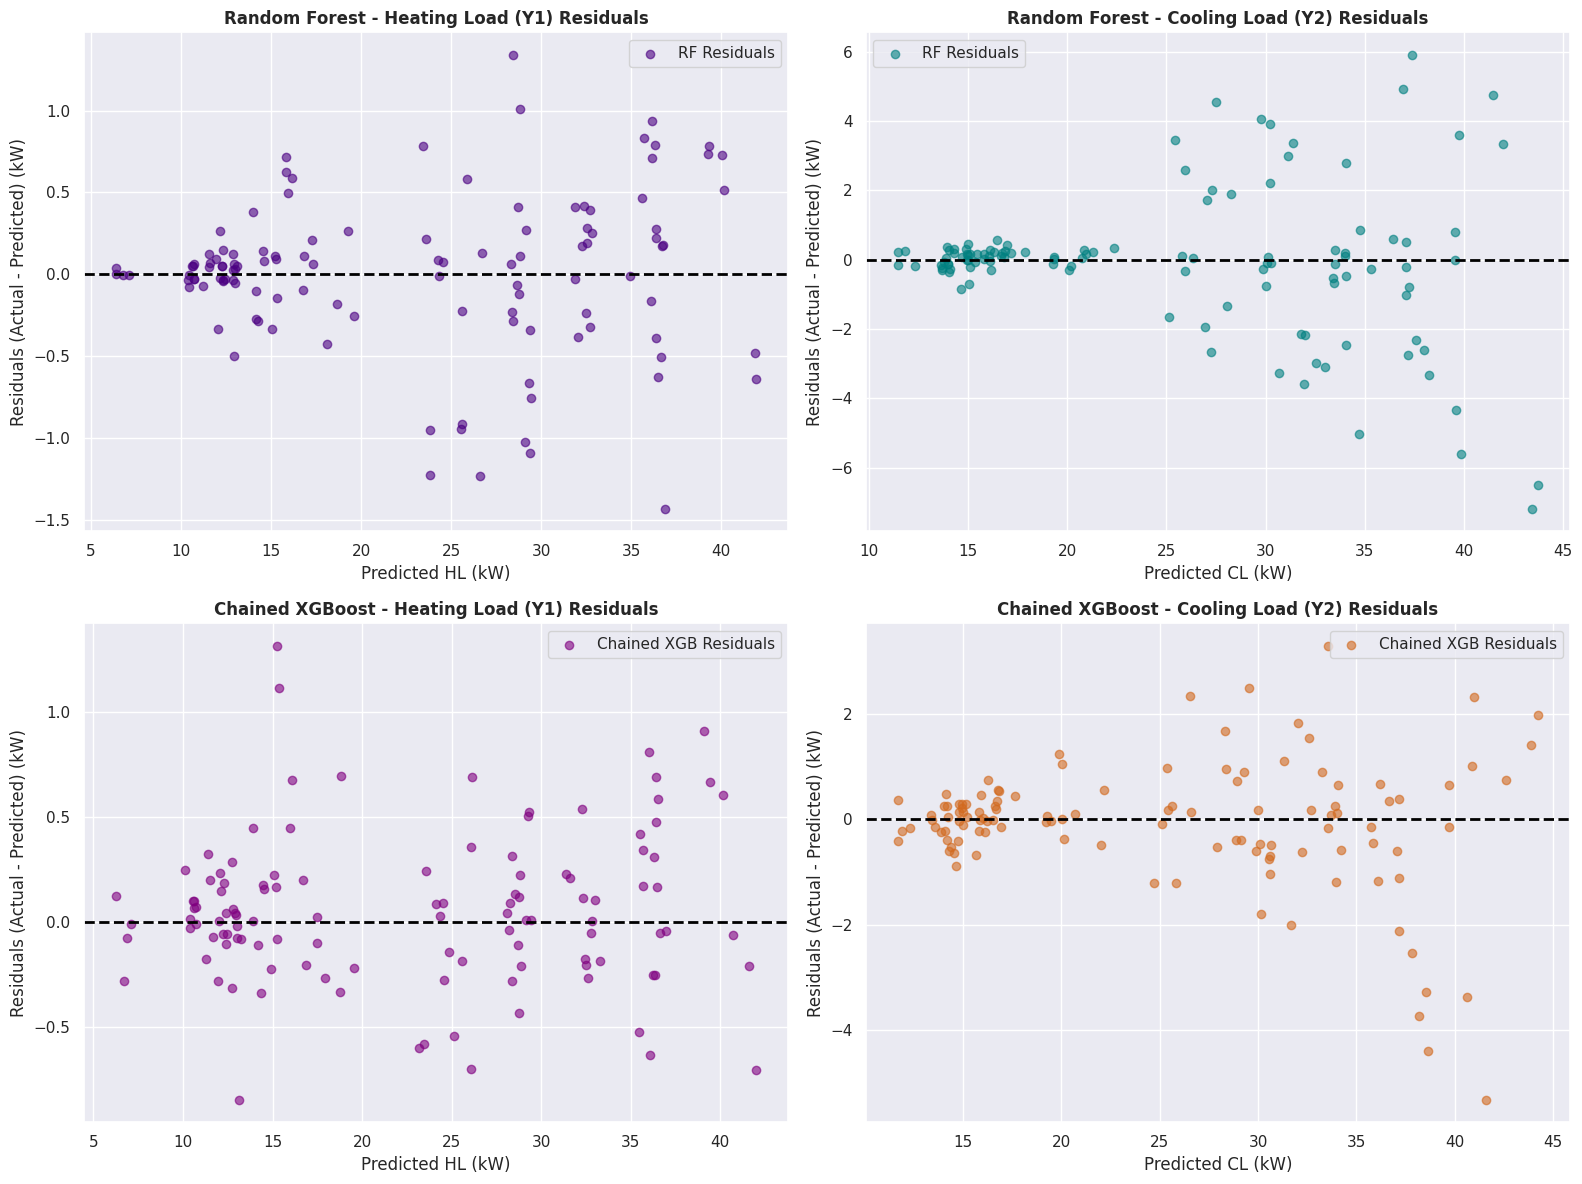

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configure styling
sns.set_theme(style='darkgrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Calculate Residuals (Actual - Predicted)
rf_residuals_y1 = y_test[:, 0] - y_test_pred[:, 0]
rf_residuals_y2 = y_test[:, 1] - y_test_pred[:, 1]
xgb_residuals_y1 = y_test[:, 0] - y1_test_pred
xgb_residuals_y2 = y_test[:, 1] - y2_test_pred

# --- ROW 1: Random Forest Baseline Residuals ---
# RF Heating Load (Y1) Residuals
axes[0, 0].scatter(y_test_pred[:, 0], rf_residuals_y1, alpha=0.6, color='indigo', label='RF Residuals')
axes[0, 0].axhline(y=0, color='black', linestyle='--', lw=2)
axes[0, 0].set_title('Random Forest - Heating Load (Y1) Residuals', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Predicted HL (kW)')
axes[0, 0].set_ylabel('Residuals (Actual - Predicted) (kW)')
axes[0, 0].legend()

# RF Cooling Load (Y2) Residuals
axes[0, 1].scatter(y_test_pred[:, 1], rf_residuals_y2, alpha=0.6, color='teal', label='RF Residuals')
axes[0, 1].axhline(y=0, color='black', linestyle='--', lw=2)
axes[0, 1].set_title('Random Forest - Cooling Load (Y2) Residuals', fontweight='bold', fontsize=12)
axes[0, 1].set_xlabel('Predicted CL (kW)')
axes[0, 1].set_ylabel('Residuals (Actual - Predicted) (kW)')
axes[0, 1].legend()

# --- ROW 2: Chained XGBoost Residuals ---
# XGB Chained Heating Load (Y1) Residuals
axes[1, 0].scatter(y1_test_pred, xgb_residuals_y1, alpha=0.6, color='purple', label='Chained XGB Residuals')
axes[1, 0].axhline(y=0, color='black', linestyle='--', lw=2)
axes[1, 0].set_title('Chained XGBoost - Heating Load (Y1) Residuals', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('Predicted HL (kW)')
axes[1, 0].set_ylabel('Residuals (Actual - Predicted) (kW)')
axes[1, 0].legend()

# XGB Chained Cooling Load (Y2) Residuals
axes[1, 1].scatter(y2_test_pred, xgb_residuals_y2, alpha=0.6, color='chocolate', label='Chained XGB Residuals')
axes[1, 1].axhline(y=0, color='black', linestyle='--', lw=2)
axes[1, 1].set_title('Chained XGBoost - Cooling Load (Y2) Residuals', fontweight='bold', fontsize=12)
axes[1, 1].set_xlabel('Predicted CL (kW)')
axes[1, 1].set_ylabel('Residuals (Actual - Predicted) (kW)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Observations

Analyzing the side-by-side **Residual Plots** (Actual - Predicted) for both models reveals several diagnostic differences:

* **Heating Load ($Y1$) Residuals**: Both the **Random Forest** (top-left) and **Chained XGBoost** (bottom-left) models display tight, randomly scattered residuals centered around the zero-error line. This indicates that both models predict Heating Load cleanly, with minimal systematic bias or heteroscedasticity.
* **Cooling Load ($Y2$) Residuals**:
  * For **Random Forest** (top-right), we observe severe scatter spreading outwards at higher predicted values (above $30$ kW), showing clear heteroscedasticity and several large positive/negative errors.
  * For **Chained XGBoost** (bottom-right), while some variance at higher cooling loads remains, the residual spread is visibly compressed. The model succeeds in pulling outlier predictions closer to the zero-error line, demonstrating how the chained auxiliary input helps stabilize predictions for the more volatile cooling load target.

## Random Forest vs. Chained XGBoost Performance

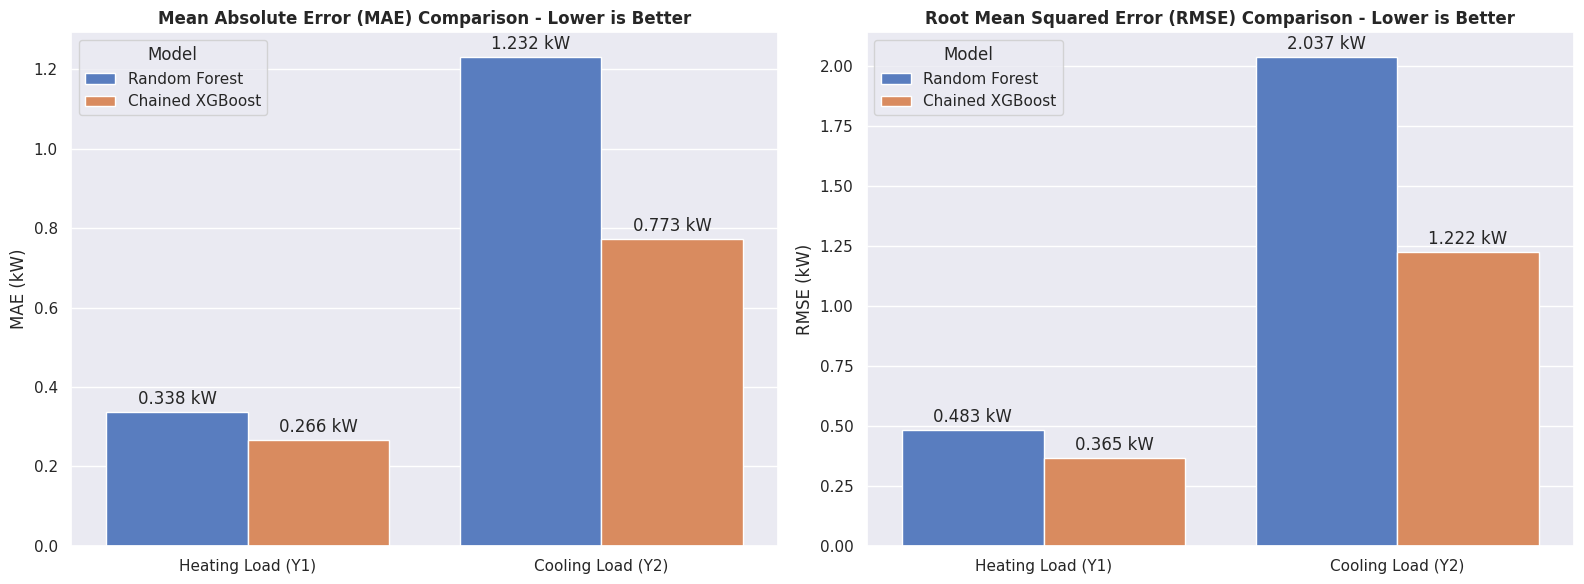

In [ ]:
metrics_data = {
    'Model': ['Random Forest', 'Random Forest', 'Chained XGBoost', 'Chained XGBoost',
              'Random Forest', 'Random Forest', 'Chained XGBoost', 'Chained XGBoost'],
    'Target': ['Heating Load (Y1)', 'Cooling Load (Y2)', 'Heating Load (Y1)', 'Cooling Load (Y2)',
               'Heating Load (Y1)', 'Cooling Load (Y2)', 'Heating Load (Y1)', 'Cooling Load (Y2)'],
    'Metric Type': ['MAE', 'MAE', 'MAE', 'MAE', 'RMSE', 'RMSE', 'RMSE', 'RMSE'],
    'Error (kW)': [0.3377, 1.2320, 0.2656, 0.7731, 0.4826, 2.0370, 0.3654, 1.2225]
}

df_compare = pd.DataFrame(metrics_data)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style='darkgrid')

# Plot MAE Comparison
sns.barplot(x='Target', y='Error (kW)', hue='Model', data=df_compare[df_compare['Metric Type'] == 'MAE'],
            ax=axes[0], palette='muted')
axes[0].set_title('Mean Absolute Error (MAE) Comparison - Lower is Better', fontweight='bold', fontsize=12)
axes[0].set_ylabel('MAE (kW)')
axes[0].set_xlabel('')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.3f kW', padding=3)

# Plot RMSE Comparison
sns.barplot(x='Target', y='Error (kW)', hue='Model', data=df_compare[df_compare['Metric Type'] == 'RMSE'],
            ax=axes[1], palette='muted')
axes[1].set_title('Root Mean Squared Error (RMSE) Comparison - Lower is Better', fontweight='bold', fontsize=12)
axes[1].set_ylabel('RMSE (kW)')
axes[1].set_xlabel('')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.3f kW', padding=3)

plt.tight_layout()
plt.show()

### Observation
Chained XGBoost consistently outperformed the Random Forest baseline for both Heating Load (Y1) and Cooling Load (Y2).

* **Heating Load (Y1):** MAE decreased from **0.338 kW** to **0.266 kW** (a **21.3%** error reduction), while RMSE decreased from **0.483 kW** to **0.365 kW** (a **24.4%** error reduction).
* **Cooling Load (Y2):** MAE decreased from **1.232 kW** to **0.773 kW** (a **37.3%** error reduction), while RMSE decreased from **2.037 kW** to **1.223 kW** (a **39.9%** error reduction).

Although Cooling Load exhibited higher prediction errors overall in both models due to its higher natural thermodynamic variance, the chained approach achieved greater relative improvements for this target. This confirms that modeling the sequential relationship ($Y1 \rightarrow Y2$) provides a highly significant boost to prediction accuracy.

# Comparison with the Research Paper
---

| Model | Heating Load (Y1) MAE (kW) | Cooling Load (Y2) MAE (kW) |
|---|---:|---:|
| Random Forest (Implemented Baseline) | 0.338 | 1.232 |
| Chained XGBoost (Implemented Model) | 0.266 | 0.773 |
| **TPE-XGBoost (Research Paper)** | **0.169** | **0.275** |

**Observation:** Chained XGBoost outperformed the Random Forest baseline, reducing MAE by approximately 21.3% for Heating Load and 37.3% for Cooling Load. However, the research paper's TPE-XGBoost achieved lower reported errors for both targets.

**Note:** The research paper used 10-fold cross-validation across five independent runs on the entire dataset, whereas the implemented models here were validated on an independent, held-out test split (15% of the data). Therefore, the comparison serves as an indicative benchmark rather than a directly equivalent experimental comparison.

The Random Forest baseline achieved MAE values of **0.338 kW** for Heating Load (Y1) and **1.232 kW** for Cooling Load (Y2). The implemented Chained XGBoost model significantly improved prediction accuracy, reducing MAE to **0.266 kW** and **0.773 kW**, respectively. This represents error reductions of approximately **21.3%** for Heating Load and **37.3%** for Cooling Load compared with Random Forest.

The research paper's TPE-XGBoost model reported lower MAE values of **0.169 kW** for Heating Load and **0.275 kW** for Cooling Load, achieving the overall best reported performance among the compared models.

However, because the research paper utilized 10-fold cross-validation across five independent runs on the full dataset while the implemented models were evaluated on a strictly unseen held-out test split, these results represent a highly competitive benchmark comparison.